# CT Power Harvesting: Post Field Trial Degradation

## Question
Has exposure during the POC 2 field trial (visible rust on the CT cores) reduced
harvested power compared to the same CT in the same POC 2 enclosure before deployment?

### Background

Power transfer in a split core CT depends on the two core halves meeting cleanly. Notebook 01 showed that contamination and damage on the core faces introduce an air gap and sharply reduce harvested power unless high clamp force is applied, and POC 2 enclosures were designed to clamp a clean core at modest force.

Several CTs came back from the POC 2 field trial with rust on them. Re-running the pre-deployment current sweeps on the same CTs in the same setup isolates the effect of field exposure on harvesting.

### Setup

This notebook uses ct_data and ct_plots src/ modules for loading and plotting.
Analysis logic lives there while narrative is contained in the notebook.

In [4]:
%load_ext autoreload
%autoreload 2

import sys

sys.path.append("../src")

from ct_plots import (
    compare_sweeps,
    compare_sweeps_grouped,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Data and method

Each trial is recorded as a single CSV in `data/raw/` named `trial_NNN_YYYY-MM-DD.csv`. Line current is swept 2 to 10 A in 1 A steps into a 5 V load at room temperature, matching the pre-deployment trials. Harvested power is the measured response.

Loading and validation are handled by `load_trial()` in `ct_data.py`: it reads the raw CSV, derives `power_mW` from output current and load voltage and validates the schema before returning. Plotting goes through `ct_plots.py`.

### Deployed units and available baselines

| Unit | CT | PCB | Before trial | Before setup | Retest |
|---|---|---|---|---|---|
| Unit 1 | B57322 | b2d1 | 015 | POC 2 clamp slice | Yes |
| Unit 2 | N9894 (bobbin) | b20a | none | not in specimen registry | No baseline |
| Unit 3 | N9902 (bobbin) | b384 | 019 (016) | POC 2 full unit (clamp slice) | Yes |
| Unit 4 | N9903 | b2d4 | 017 (014) | POC 2 full unit (clamp slice) | Yes |
| Unit 5 | B57321 | b2d3 | 015 | POC 2 clamp slice | Yes |
| Unit 6 | N9895 (bobbin) | b2d9 | 013 | Force gauge @ 100 N | Optional, force gauge only |
| Sample Unit | unknown | – | – | missing ground rivnut | Clarify, N9902 confirmed in Unit 3 |

Each CT is retested in the same setup as its baseline so the before/after comparison is like for like. Units 3 and 4 have full unit baselines and can be tested as returned from the field. Units 1 and 5 only have clamp slice baselines.

### Baseline power (pre-deployment)

| CT | Trial | Setup | Power @ 5 A (mW) | Power @ 10 A (mW) |
|---|---|---|---|---|
| N9903 | 017 | POC 2 full unit | 92.3 | 188.4 |
| N9903 | 014 | POC 2 clamp slice | 84.0 | 183.3 |
| N9902 | 019 | POC 2 full unit | 95.2 | 190.8 |
| N9902 | 016 | POC 2 clamp slice | 95.0 | 191.2 |
| B57321 | 015 | POC 2 clamp slice | 94.8 | 189.3 |
| B57322 | 015 | POC 2 clamp slice | 91.5 | 194.4 |

### Caveats

- N9903's two baselines differ by almost 2x at 2 A (15 mW slice vs 28 mW full unit), so low current comparisons for that CT carry more noise.
- Trial 021 (N9903 temperature sweep) has no recorded enclosure. If it was the full unit, its 23 °C sweep (83.3 mW @ 5 A) is a second N9903 baseline.
- Trial 021 showed that temperature shifts output at 2 to 3 A, so retests should be run at room temperature.

## Findings

### Pre-deployment baselines: POC 2 full unit

Text(0.5, 0.98, 'Pre-deployment Baseline - POC 2 Full Unit')

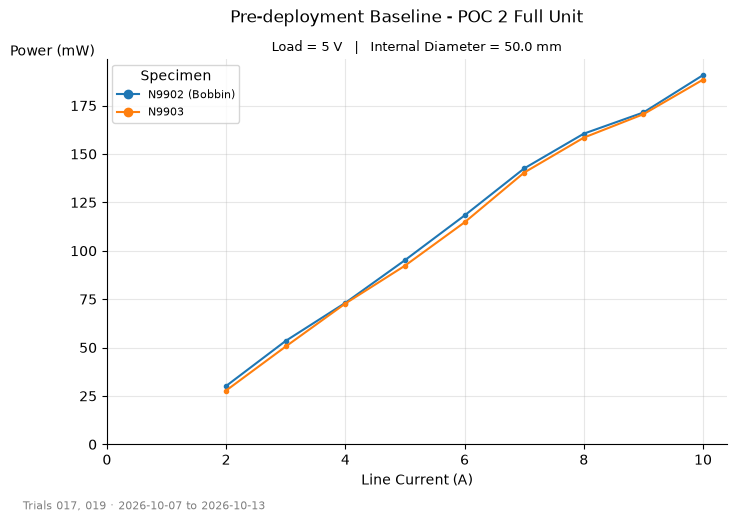

In [5]:
fig, ax = compare_sweeps(
    ["017", "019"],
    x="line_current_A",
    xlabel="Line Current (A)",
)
fig.suptitle("Pre-deployment Baseline - POC 2 Full Unit")

### Pre-deployment baselines: POC 2 clamp slice

Text(0.5, 0.98, 'Pre-deployment Baseline - POC 2 Clamp Slice')

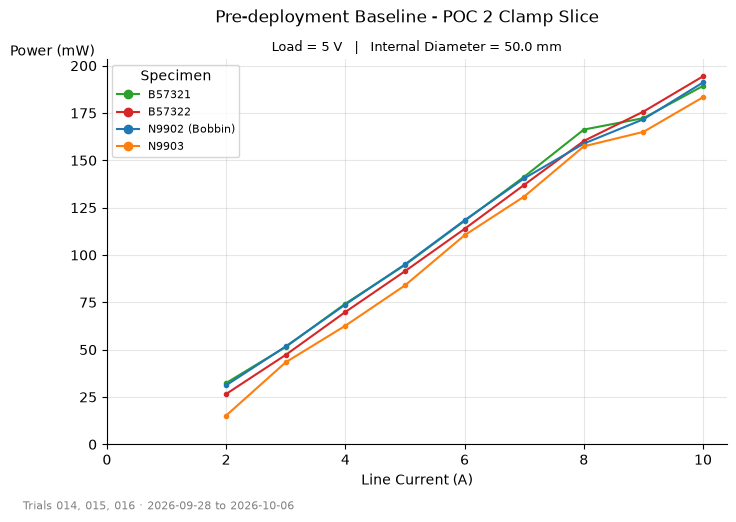

In [6]:
fig, ax = compare_sweeps(
    ["014", "015", "016"],
    x="line_current_A",
    xlabel="Line Current (A)",
)
fig.suptitle("Pre-deployment Baseline - POC 2 Clamp Slice")

### Before vs after field trial

Unit 3 (N9902): pre-deployment trial 019 vs post field trial retest, trial 025, both in the POC 2 full unit.

_Remaining units: add once retest trials are recorded._

In [ ]:
fig, ax = compare_sweeps_grouped(
    ["019", "025"],
    key_col="field_tested",
    color_map={"no": "tab:blue", "yes": "tab:red"},
    labels={
        "no": "Pre-deployment (trial 019)",
        "yes": "Post field trial (trial 025)",
    },
    legend_title="POC 2 field trial",
    x="line_current_A",
    xlabel="Line Current (A)",
)
fig.suptitle("Unit 3 Before vs After POC 2 Field Trial")
ax.set_title(
    "Load = 5 V | Internal Diameter = 50.0 mm | CT = N9902 (bobbin)",
    fontsize=9,
)
fig.savefig("../figures/unit3_pre_vs_post_field_trial.png", dpi=300, bbox_inches="tight")

### Next steps

- Confirm which CT, if any, is in the Sample Unit.
- Check the N9894 label, it has no record in `specimens.csv`.
- Retest Units 3 and 4 in the full unit, and Units 1 and 5 in a clamp slice, 2 to 10 A into 5 V at room temperature.
- Optionally retest N9895 (Unit 6) on the force gauge at 100 N against trial 013.
- Record visible rust / contamination on each core face before testing.